# Problema 4 — Classificação de Risco de Crédito Utilizando Árvores de Decisão

A concessão de crédito é uma das decisões mais sensíveis do sistema financeiro: aprovar um cliente inadimplente gera prejuízo direto, mas recusar um bom pagador significa perda de receita e exclusão financeira. Diferentemente de outras aplicações de machine learning, aqui não basta acertar, é preciso justificar a decisão. A LGPD (Lei 13.709/2018), em seu Art. 20, assegura ao titular o direito de solicitar a revisão de decisões tomadas exclusivamente com base em tratamento automatizado, o que torna modelos interpretáveis especialmente valiosos nesse domínio.

É exatamente esse o apelo da árvore de decisão: o modelo aprendido pode ser lido como um conjunto de regras de produção, uma explicação que um analista, um cliente ou um auditor consegue compreender sem conhecimento de estatística. No Brasil, iniciativas como o Cadastro Positivo, o Open Finance e programas de microcrédito produtivo orientado como o Crediamigo, do Banco do Nordeste, dependem de avaliações de risco em larga escala, tornando o problema próximo da nossa realidade.

Neste projeto, você é convidado a construir um modelo de classificação de solicitantes de crédito em duas categorias de risco (bom pagador e mau pagador) a partir de dados cadastrais e financeiros, utilizando uma Árvore de Decisão (Decision Tree).

O projeto utiliza o arquivo `german.data` do dataset [Statlog (German Credit Data)](https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data). O dataset foi doado por Hans Hofmann (Universidade de Hamburgo, Alemanha) em 1994 e reúne 1.000 solicitações de crédito reais de um banco alemão. Cada amostra é descrita por 20 atributos: 7 numéricos e 13 categóricos. Entre os atributos, temos duração do empréstimo em meses, valor solicitado, histórico de crédito, finalidade do empréstimo, saldo em conta corrente, tempo de emprego atual, idade, número de créditos ativos e existência de garantias. O rótulo indica se o cliente representou, de fato, um bom risco (700 amostras) ou um mau risco (300 amostras) de crédito.

**Observação:** os atributos categóricos do arquivo `german.data` aparecem codificados (`A11`, `A12`, ...), com o significado de cada código descrito no arquivo `german.doc`. Alternativamente, a versão com rótulos legíveis pode ser obtida diretamente via `sklearn.datasets.fetch_openml(name='credit-g', version=1)`.

Realize as seguintes tarefas utilizando o dataset fornecido:

## 1. Preparação dos dados

Carregue o dataset, identifique quais atributos são numéricos e quais são categóricos. Verifique se existe necessidade de codificação adequada às variáveis categóricas (one-hot encoding ou ordinal encoding). Avalie o balanceamento entre as classes e comente o impacto de um conjunto desbalanceado (70%/30%) sobre a interpretação da acurácia.

In [1]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
import pandas as pd

In [2]:
plt.rcParams["font.family"] = "Arial"
plt.rcParams["mathtext.fontset"] = "custom"
plt.rcParams['mathtext.rm'] = "Arial"
plt.rcParams['mathtext.it'] = "Arial:italic"
plt.rcParams['mathtext.bf'] = "Arial:bold"
plt.rcParams['figure.figsize'] = (8, 5)

In [3]:
from sklearn.datasets import fetch_openml

# Baixa a versão com os rótulos legíveis
dados = fetch_openml(name='credit-g', version=1, as_frame=True)

X = dados.data
y = dados.target

X.head()

,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,residence_since,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,4,real estate,67,none,own,2,skilled,1,yes,yes
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,2,real estate,22,none,own,1,skilled,1,none,yes
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,3,real estate,49,none,own,1,unskilled resident,2,none,yes
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,4,life insurance,45,none,for free,1,skilled,2,none,yes
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,4,no known property,53,none,for free,2,skilled,2,none,yes


##### Categóricos = 13, sendo 2 binários
##### Numéricos = 7

In [4]:
X = pd.get_dummies(X, dtype=int)
X.head()

,duration,credit_amount,installment_commitment,residence_since,age,existing_credits,num_dependents,checking_status_0<=X<200,checking_status_<0,checking_status_>=200,...,housing_own,housing_rent,job_high qualif/self emp/mgmt,job_unemp/unskilled non res,job_unskilled resident,job_skilled,own_telephone_none,own_telephone_yes,foreign_worker_no,foreign_worker_yes
0,6,1169,4,4,67,2,1,0,1,0,...,1,0,0,0,0,1,0,1,0,1
1,48,5951,2,2,22,1,1,1,0,0,...,1,0,0,0,0,1,1,0,0,1
2,12,2096,2,3,49,1,2,0,0,0,...,1,0,0,0,1,0,1,0,0,1
3,42,7882,2,4,45,1,2,0,1,0,...,0,0,0,0,0,1,1,0,0,1
4,24,4870,3,4,53,2,2,0,1,0,...,0,0,0,0,0,1,1,0,0,1


In [5]:
y.head()

0    good
1     bad
2    good
3    good
4     bad
Name: class, dtype: category
Categories (2, str): ['bad', 'good']

In [6]:
print("Proporções no conjunto total:")
print((y.value_counts(normalize=True) * 100).round(2))

Proporções no conjunto total:
class
good    70.0
bad     30.0
Name: proportion, dtype: float64


### Resposta — item 1

Sete atributos são numéricos; os outros 13 são categóricos, sendo dois deles binários. Usei one-hot encoding para representar as categorias numericamente.

A base tem 70% de bons pagadores e 30% de maus pagadores. Um classificador que fosse simplesmente um print(“bom pagador”) já teria 70% de acurácia, embora não identificasse nenhum mau pagador. Por isso, é necessário observar também a matriz de confusão e as métricas por classe.

O desbalanceamento é tratado com `class_weight="balanced"`, que aumenta o peso da classe menos frequente durante o ajuste. Não são criadas amostras sintéticas. Para que esse ódio contra as sintéticas? Estavam dando alguns resultados estranhos nas regras da árvore.

## 2. Normalização dos atributos

Justifique por que a normalização dos atributos não é necessária para uma árvore de decisão.

### Resposta — item 2

A árvore não calcula distâncias entre dados. Ela escolhe divisões como “valor do empréstimo ≤ um limite”. Uma padronização ou normalização não altera em nada a funcionalidade do modelo, apenas muda o valor numérico do limite. Por isso, não é necessário colocar os atributos na mesma escala para treinar a árvore.

## 3. Divisão treino/teste

Divida os dados em 80% para treino e 20% para teste, utilizando divisão estratificada para garantir que a proporção das duas classes seja mantida em ambos os conjuntos.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

# As classes recebem pesos no modelo; não são criadas amostras sintéticas.

print("Proporções no conjunto total:")
print((y.value_counts(normalize=True) * 100).round(2))

print("\nProporções no treino:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nProporções no teste:")
print((y_test.value_counts(normalize=True) * 100).round(2))


Proporções no conjunto total:
class
good    70.0
bad     30.0
Name: proportion, dtype: float64

Proporções no treino:
class
good    70.0
bad     30.0
Name: proportion, dtype: float64

Proporções no teste:
class
good    70.0
bad     30.0
Name: proportion, dtype: float64


## 4. Treinamento e controle de complexidade

Treine árvores com diferentes valores de profundidade máxima (ex.: 2, 3, 5, 7, 10 e sem limite), utilizando validação cruzada de 5 folds sobre o conjunto de treino. Plote, em um mesmo gráfico, a acurácia média de treino e a de validação em função da profundidade, e escolha o valor com melhor desempenho. O que acontece com o modelo para profundidades muito baixas e muito altas? Relacione sua resposta aos conceitos de underfitting e overfitting. Repita o experimento trocando o critério de divisão dos nós de Gini para entropia e comente se houve diferença relevante.

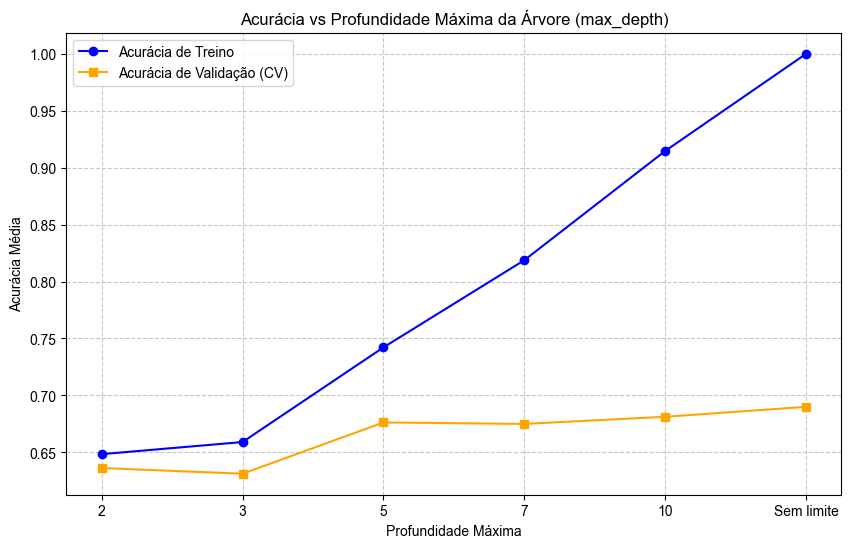

A melhor profundidade máxima encontrada foi: None com acurácia de validação de 0.6900


In [8]:
from sklearn.model_selection import cross_validate
import numpy as np
profundidades = [2, 3, 5, 7, 10, None]

train_scores = []
val_scores = []

for prof in profundidades:
    tree = DecisionTreeClassifier(criterion="gini", max_depth=prof, random_state=42, class_weight="balanced")
    
    cv_results = cross_validate(tree, X_train, y_train, cv=5, return_train_score=True, scoring='accuracy')
    
    train_scores.append(np.mean(cv_results['train_score']))
    val_scores.append(np.mean(cv_results['test_score']))

labels_x = [str(p) if p is not None else 'Sem limite' for p in profundidades]

plt.figure(figsize=(10, 6))
plt.plot(labels_x, train_scores, marker='o', label='Acurácia de Treino', color='blue')
plt.plot(labels_x, val_scores, marker='s', label='Acurácia de Validação (CV)', color='orange')

plt.title('Acurácia vs Profundidade Máxima da Árvore (max_depth)')
plt.xlabel('Profundidade Máxima')
plt.ylabel('Acurácia Média')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

melhor_idx = np.argmax(val_scores)
melhor_profundidade = profundidades[melhor_idx]
print(f"A melhor profundidade máxima encontrada foi: {melhor_profundidade} com acurácia de validação de {val_scores[melhor_idx]:.4f}")

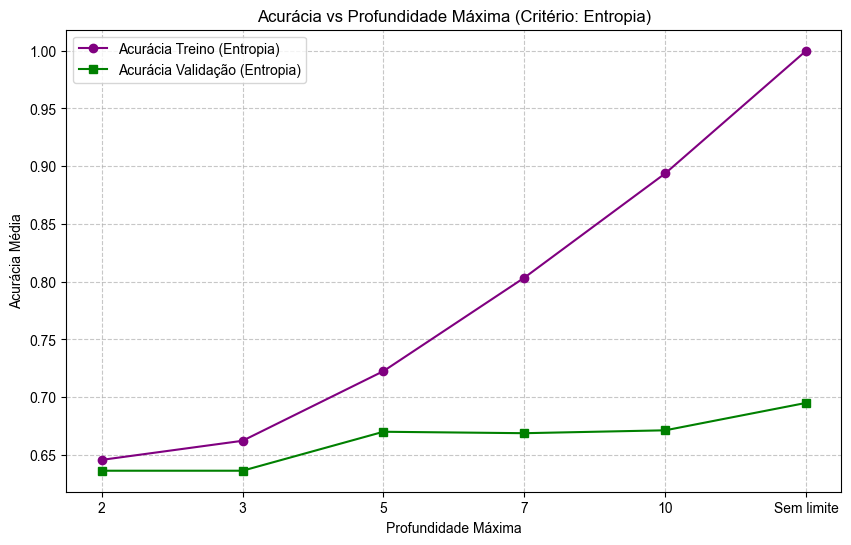

A melhor profundidade máxima com Entropia foi: None com acurácia de validação de 0.6950


In [9]:
train_scores_ent = []
val_scores_ent = []

for prof in profundidades:
    tree_ent = DecisionTreeClassifier(criterion='entropy', max_depth=prof, random_state=42, class_weight="balanced")
    
    cv_results_ent = cross_validate(tree_ent, X_train, y_train, cv=5, return_train_score=True, scoring='accuracy')
    
    train_scores_ent.append(np.mean(cv_results_ent['train_score']))
    val_scores_ent.append(np.mean(cv_results_ent['test_score']))

labels_x = [str(p) if p is not None else 'Sem limite' for p in profundidades]

plt.figure(figsize=(10, 6))
plt.plot(labels_x, train_scores_ent, marker='o', label='Acurácia Treino (Entropia)', color='purple')
plt.plot(labels_x, val_scores_ent, marker='s', label='Acurácia Validação (Entropia)', color='green')

plt.title('Acurácia vs Profundidade Máxima (Critério: Entropia)')
plt.xlabel('Profundidade Máxima')
plt.ylabel('Acurácia Média')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

melhor_idx_ent = np.argmax(val_scores_ent)
print(f"A melhor profundidade máxima com Entropia foi: {profundidades[melhor_idx_ent]} com acurácia de validação de {val_scores_ent[melhor_idx_ent]:.4f}")

### Resposta — item 4

Profundidades muito baixas limitam a quantidade de regras, aproximando-se do underfitting: uma árvore preguiçosa. Ao aumentar a profundidade, a árvore distingue situações cada vez mais específicas, aproximando-se do overfitting. Com uma quantidade muito grande de regras, o grau de pureza chega ao máximo, ou próximo disso, nas folhas.

Não houve quase nenhuma diferença entre Gini e a entropia.

## 5. Interpretação do modelo

Usando a árvore com a profundidade escolhida, gere a visualização gráfica da árvore e a lista de importância dos atributos. Responda: quais são os três atributos mais determinantes para a classificação? Escreva, em linguagem natural, o conjunto de regras correspondente ao caminho que leva da raiz até a folha com maior número de amostras de mau risco.

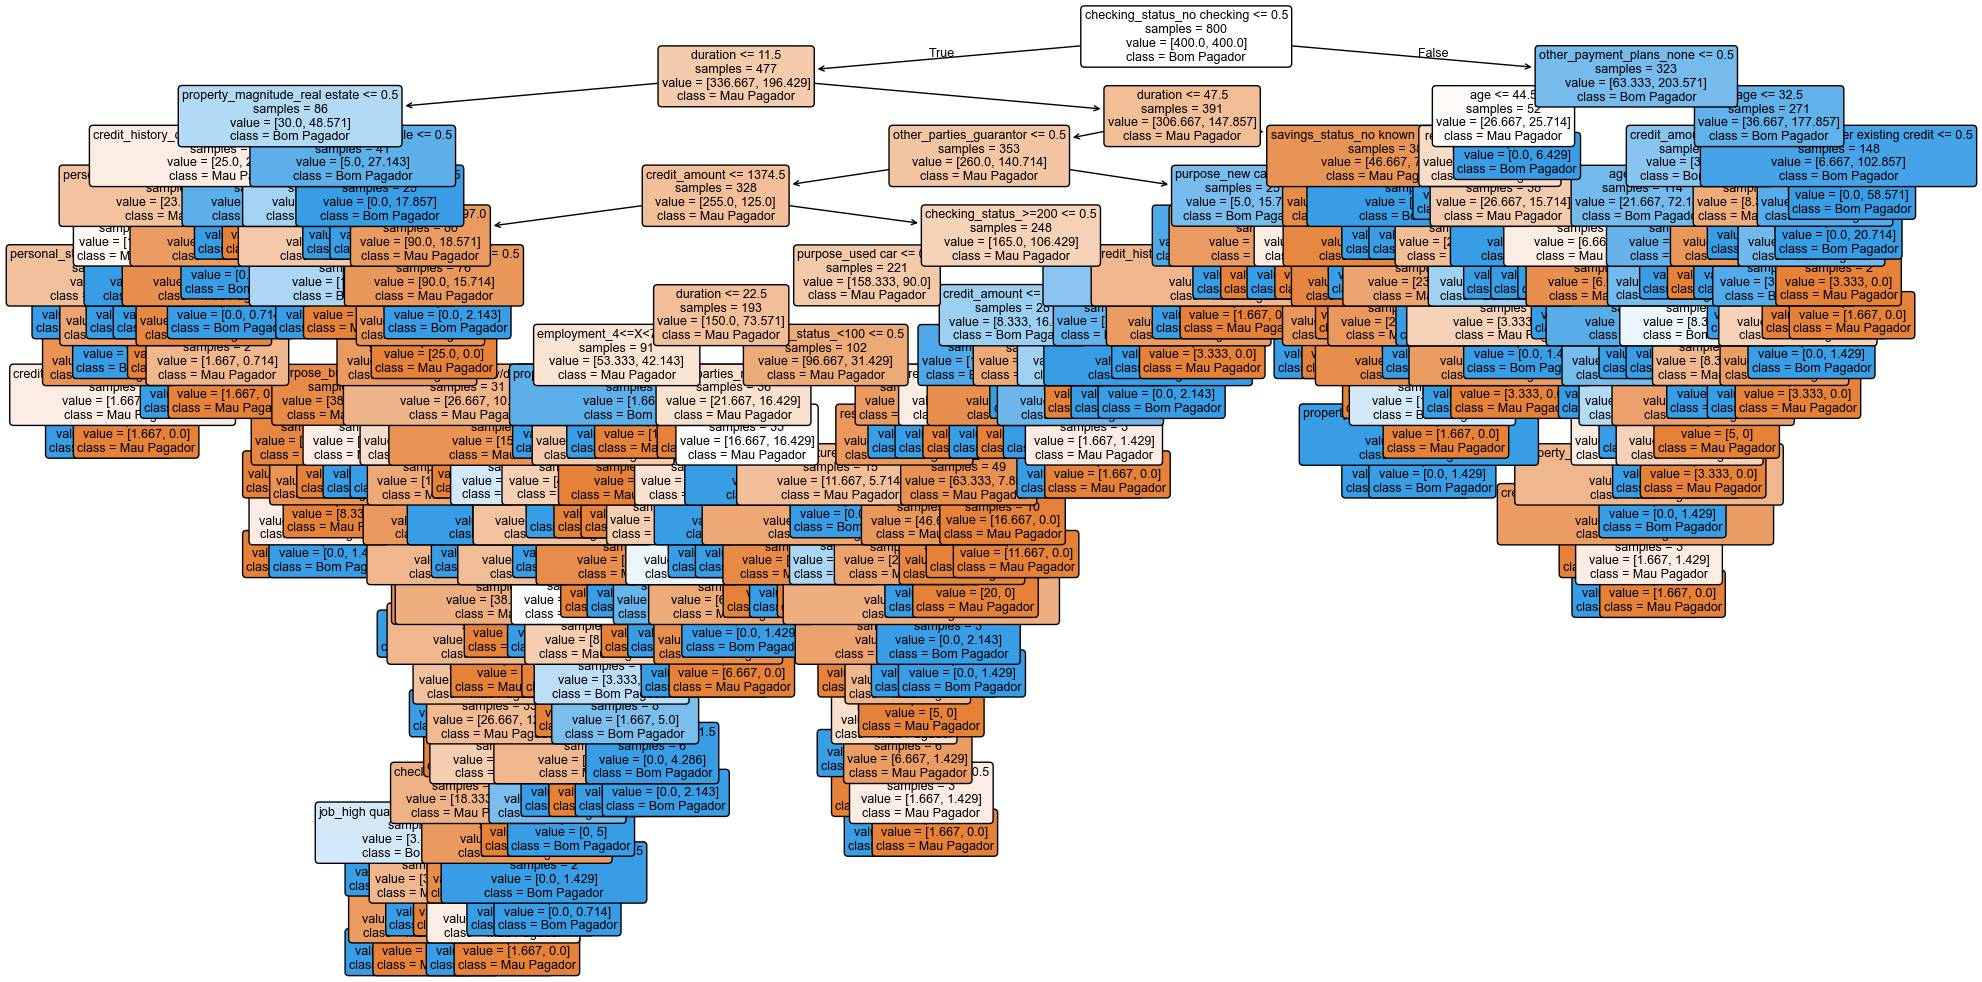

In [10]:
model = DecisionTreeClassifier(criterion="entropy", max_depth=profundidades[melhor_idx_ent], random_state=42, class_weight="balanced")
model.fit(X_train, y_train)

nomes_features = X.columns.tolist()
nomes_classes = [{"bad": "Mau Pagador", "good": "Bom Pagador"}[c] for c in model.classes_] 

fig, ax = plt.subplots(figsize=(20, 10)) 
plot_tree(
        model,
        feature_names=nomes_features,
        class_names=nomes_classes,
        filled=True,
        impurity=False,
        rounded=True,
        fontsize=9,
        ax=ax
    )
fig.tight_layout()
plt.show()

## 6. Avaliação do modelo

Utilizando o conjunto de teste, calcule a matriz de confusão e as métricas de acurácia, precisão, recall e F1-score para cada classe. Responda: qual tipo de erro o modelo comete com mais frequência e por que ele é o mais grave nesta aplicação? Que ajuste você faria no treinamento para reduzi-lo?

In [11]:
y_prev = model.predict(X_test)

metricas = classification_report(y_test, y_prev)
print("\nMétricas por Classe:")
print(metricas)


Métricas por Classe:
              precision    recall  f1-score   support

         bad       0.46      0.50      0.48        60
        good       0.78      0.75      0.76       140

    accuracy                           0.68       200
   macro avg       0.62      0.62      0.62       200
weighted avg       0.68      0.68      0.68       200



In [12]:
print(confusion_matrix(y_test, y_prev))
print(f"Acurácia: {accuracy_score(y_test, y_prev):.4f}")

[[ 30  30]
 [ 35 105]]
Acurácia: 0.6750


### Resposta — item 6

Com entropia, o modelo acertou **30 maus pagadores e 105 bons pagadores**; classificou **30 maus como bons** e **35 bons como maus**.

O erro mais frequente é classificar um bom pagador como mau. Ele não é o mais grave: mais grave seria classificar um mau pagador como um bom, o que vai resultar numa perda de investimento; afinal, ele não vai pagar a dívida.

Talvez uma forma de diminuir o erro de classificar maus como bons seria tentar desbalancear, deixando mais amostras como maus pagadores do que como bons pagadores.

In [13]:
importancias = pd.Series(model.feature_importances_, index=nomes_features).sort_values(ascending=False)
print("Importância dos atributos:")
display(importancias)
print("Três atributos mais importantes:")
display(importancias.head(3))

Importância dos atributos:


credit_amount                   0.144798
checking_status_no checking     0.103554
duration                        0.101061
age                             0.087279
residence_since                 0.038462
                                  ...   
personal_status_male div/sep    0.000000
housing_for free                0.000000
job_unemp/unskilled non res     0.000000
foreign_worker_no               0.000000
foreign_worker_yes              0.000000
Length: 61, dtype: float64

Três atributos mais importantes:


credit_amount                  0.144798
checking_status_no checking    0.103554
duration                       0.101061
dtype: float64

### Resposta — item 5: importância dos atributos

As três variáveis com maior importância na árvore atual foram:

1. `credit_amount`: **0,1448** (14,48%), valor solicitado;
2. `checking_status_no checking`: **0,1036** (10,36%), indicador de ausência de conta corrente;
3. `duration`: **0,1011** (10,11%), duração do empréstimo.

### Resposta — item 5: caminho até a folha com mais maus pagadores

A ordem de `model.classes_` é **`['bad', 'good']`**. Contando diretamente os rótulos originais dos registros de treino que chegam a cada folha, a folha com mais maus pagadores é a que tem **22 clientes, todos maus pagadores**, e entropia zero.

O caminho exato é:

1. `checking_status_no checking <= 0.5`: **True**;
2. `duration <= 11.5`: **False**;
3. `duration <= 47.5`: **False**;
4. `savings_status_no known savings <= 0.5`: **True**;
5. `residence_since <= 1.5`: **False**;
6. `employment_unemployed <= 0.5`: **True**;
7. `credit_amount <= 5191.5`: **False**.

**Em linguagem natural:** se o cliente possui conta corrente, solicita um empréstimo com duração superior a 47,5 meses, não está na categoria “sem poupança conhecida”, reside no endereço atual há mais de 1,5 ano, não está na categoria “desempregado” e solicita mais de 5.191,5 unidades monetárias, a árvore o classifica como **mau pagador**.

In [15]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# 1. Defina uma área de desenho (figsize) bem grande
fig, ax = plt.subplots(figsize=(200, 100)) 

# 2. Gere o desenho da árvore
plot_tree(
    model,  # A sua árvore treinada
    feature_names=X.columns.tolist(),
    class_names=[{"bad": "Mau Pagador", "good": "Bom Pagador"}[c] for c in model.classes_],
    filled=True,
    rounded=True,
    fontsize=9, # Como o PDF aceita zoom, a fonte pode ser pequena
    ax=ax
)

# 3. Exporte a imagem para PDF (CRÍTICO: fazer isso antes do plt.show)
plt.savefig("arvore_gigante.pdf", format="pdf", bbox_inches="tight")
